# Dataset Source
*Dataset: House Price Prediction Dataset
*Source: Kaggle  House Price Prediction Dataset
*Source Link: https://www.kaggle.com/code/mahmoudhassanmahmoud/house-price-regression/input
The House Sales in King County dataset contains information about residential properties, including the number of bedrooms and bathrooms, living area, lot area, number of floors, waterfront status, property condition, construction grade, year built, location, and house price. The dataset can be used to study the relationship between property characteristics and house prices. For this activity, `sqft_living` is used as the input feature and `price` is used as the target variable.

In [4]:
import pandas as pd

In [5]:
import numpy as np

In [6]:
import matplotlib.pyplot as plt

In [7]:

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [ ]:
df = pd.read_csv("houses.csv")
df.head()

,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,price
0,3,1.00,1180,5650,1.0,0,0,3,7,1180,0,1955,0,98178,47.5112,-122.257,1340,22.19
1,3,2.25,2570,7242,2.0,0,0,3,7,2170,400,1951,1991,98125,47.7210,-122.319,1690,53.80
2,2,1.00,770,10000,1.0,0,0,3,6,770,0,1933,0,98028,47.7379,-122.233,2720,18.00
3,4,3.00,1960,5000,1.0,0,0,5,7,1050,910,1965,0,98136,47.5208,-122.393,1360,60.40
4,3,2.00,1680,8080,1.0,0,0,3,8,1680,0,1987,0,98074,47.6168,-122.045,1800,51.00


In [9]:
df.tail()

,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,price
994,2,1.00,740,6460,1.0,0,0,3,6,740,0,1953,0,98146,47.5077,-122.344,1170,17.850
995,4,2.50,1860,6325,2.0,0,0,4,7,1860,0,1991,0,98038,47.3492,-122.030,1860,29.100
996,2,2.75,1590,20917,1.5,0,0,3,5,1590,0,1920,0,98001,47.2786,-122.250,1310,19.995
997,2,1.00,850,2340,1.0,0,0,3,7,850,0,1922,0,98105,47.6707,-122.328,1300,55.350
998,2,1.00,1030,4188,1.0,0,0,3,8,1030,0,1981,0,98038,47.3738,-122.057,1450,18.995


In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 999 entries, 0 to 998
Data columns (total 18 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   bedrooms       999 non-null    int64  
 1   bathrooms      999 non-null    float64
 2   sqft_living    999 non-null    int64  
 3   sqft_lot       999 non-null    int64  
 4   floors         999 non-null    float64
 5   waterfront     999 non-null    int64  
 6   view           999 non-null    int64  
 7   condition      999 non-null    int64  
 8   grade          999 non-null    int64  
 9   sqft_above     999 non-null    int64  
 10  sqft_basement  999 non-null    int64  
 11  yr_built       999 non-null    int64  
 12  yr_renovated   999 non-null    int64  
 13  zipcode        999 non-null    int64  
 14  lat            999 non-null    float64
 15  long           999 non-null    float64
 16  sqft_living15  999 non-null    int64  
 17  price          999 non-null    float64
dtypes: float64

In [11]:
df.describe()

,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,price
count,999.000000,999.000000,999.000000,999.000000,999.000000,999.000000,999.000000,999.000000,999.000000,999.000000,999.000000,999.000000,999.000000,999.000000,999.000000,999.000000,999.000000,999.000000
mean,3.349349,2.045796,2051.397397,14707.242242,1.446947,0.008008,0.237237,3.464464,7.605606,1750.233233,301.164164,1969.030030,81.830831,98074.441441,47.549720,-122.207406,1986.813814,52.071452
std,0.852367,0.721983,888.351113,28975.077254,0.517420,0.089173,0.765472,0.689521,1.160734,790.466905,451.023402,28.198607,395.767918,52.545832,0.141558,0.139564,670.723475,33.974907
min,0.000000,0.000000,380.000000,649.000000,1.000000,0.000000,0.000000,1.000000,4.000000,380.000000,0.000000,1900.000000,0.000000,98001.000000,47.177500,-122.490000,830.000000,8.000000
25%,3.000000,1.500000,1405.000000,5419.000000,1.000000,0.000000,0.000000,3.000000,7.000000,1190.000000,0.000000,1952.000000,0.000000,98032.000000,47.443000,-122.322500,1490.000000,30.980000
50%,3.000000,2.000000,1900.000000,8040.000000,1.000000,0.000000,0.000000,3.000000,7.000000,1540.000000,0.000000,1974.000000,0.000000,98058.000000,47.563600,-122.218000,1850.000000,43.500000
75%,4.000000,2.500000,2475.000000,11508.500000,2.000000,0.000000,0.000000,4.000000,8.000000,2135.000000,580.000000,1992.000000,0.000000,98116.000000,47.673400,-122.118000,2360.000000,63.446250
max,7.000000,5.000000,6070.000000,315374.000000,3.500000,1.000000,4.000000,5.000000,12.000000,6070.000000,2060.000000,2015.000000,2014.000000,98199.000000,47.777600,-121.709000,4760.000000,308.000000


In [12]:
df.isnull().sum()

bedrooms         0
bathrooms        0
sqft_living      0
sqft_lot         0
floors           0
waterfront       0
view             0
condition        0
grade            0
sqft_above       0
sqft_basement    0
yr_built         0
yr_renovated     0
zipcode          0
lat              0
long             0
sqft_living15    0
price            0
dtype: int64

In [13]:
df.duplicated().sum()

np.int64(0)

In [14]:
X = df[["sqft_living"]]
y = df["price"]

print("Input Feature (X): sqft_living")
print("Target (y): price")
print("Number of records:", len(df))

Input Feature (X): sqft_living
Target (y): price
Number of records: 999


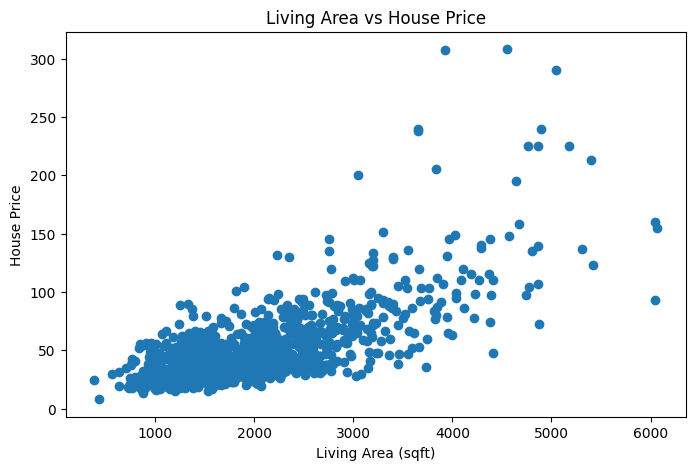

In [15]:
plt.figure(figsize=(8, 5))

plt.scatter(df["sqft_living"], df["price"])

plt.title("Living Area vs House Price")
plt.xlabel("Living Area (sqft)")
plt.ylabel("House Price")

plt.show()

In [16]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

print("Total observations:", len(df))
print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))

Total observations: 999
Training observations: 799
Testing observations: 200


In [17]:
model = LinearRegression()

model.fit(X_train, y_train)

print("Model training completed successfully.")

Model training completed successfully.


In [18]:
print("Intercept:", model.intercept_)
print("Coefficient:", model.coef_[0])

Intercept: -3.3100658777702847
Coefficient: 0.027138410088873712


In [19]:
print("Linear Regression Equation:")
print(f"price = {model.intercept_:.4f} + ({model.coef_[0]:.4f} × sqft_living)")

Linear Regression Equation:
price = -3.3101 + (0.0271 × sqft_living)


In [20]:
y_pred = model.predict(X_test)

print("Test predictions generated successfully.")
print("Number of predictions:", len(y_pred))

Test predictions generated successfully.
Number of predictions: 200


In [21]:
comparison = pd.DataFrame({
    "Actual Price": y_test.values,
    "Predicted Price": y_pred
})

comparison.head(10)

,Actual Price,Predicted Price
0,69.110,60.736582
1,24.995,32.784020
2,46.400,59.108277
3,66.500,86.789456
4,36.000,56.665820
5,53.000,59.651046
6,43.165,43.096615
7,91.000,87.603608
8,72.250,128.853991
9,47.850,53.409211


#Observation

The actual and predicted house prices show noticeable differences for several test observations. For example, a house with an actual price of 69.110 has a predicted price of approximately 60.737, while another house with an actual price of 66.500 has a predicted price of approximately 86.789.

These differences indicate that the Linear Regression model using only `sqft_living` does not perfectly predict house prices. Other factors such as location, condition, grade, number of bedrooms, and waterfront status may also influence house prices.

The predictions shown above are generated only for the 20% test dataset and were not used during model training.

In [22]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"MAE  : {mae:.4f}")
print(f"MSE  : {mse:.4f}")
print(f"RMSE : {rmse:.4f}")
print(f"R²   : {r2:.4f}")

MAE  : 14.9228
MSE  : 469.8139
RMSE : 21.6752
R²   : 0.4774


# Interpretation of Model Evaluation

The Linear Regression model achieved a Mean Absolute Error (MAE) of 14.9228, which means that the model's predictions differ from the actual house prices by approximately 14.92 price units on average.

The Mean Squared Error (MSE) is 469.8139. Since MSE squares the prediction errors, larger errors have a greater effect on this metric.

The Root Mean Squared Error (RMSE) is 21.6752, meaning that the typical prediction error is approximately 21.68 price units, with larger errors having more influence on the value.

The model obtained an R² score of 0.4774. This indicates that the model explains approximately 47.74% of the variation in house prices using only `sqft_living`. The remaining variation may be influenced by other factors such as location, number of bedrooms, condition, grade, waterfront status, and other property characteristics.

Overall, the model captures a moderate positive relationship between living area and house price, but `sqft_living` alone is not sufficient to accurately explain all variations in house prices.

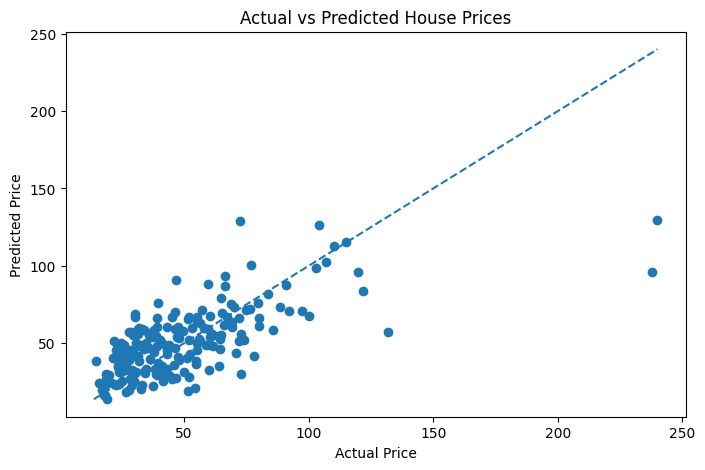

In [23]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred)

# Perfect prediction reference line
min_value = min(y_test.min(), y_pred.min())
max_value = max(y_test.max(), y_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.title("Actual vs Predicted House Prices")
plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")

plt.show()

# Interpretation of Actual vs Predicted Plot

The scatter plot compares the actual house prices with the prices predicted by the Linear Regression model. The dashed diagonal line represents perfect prediction, where the predicted price would be equal to the actual price.

Most of the observations are concentrated in the lower-to-middle price range and are relatively close to the reference line, indicating that the model captures the general relationship between `sqft_living` and house price.

However, several points are noticeably away from the reference line, particularly for some higher-priced houses. This shows that the model makes larger prediction errors for certain observations.

The spread of the points around the reference line is consistent with the R² score of 0.4774, indicating that the model explains approximately 47.74% of the variation in house prices. Therefore, `sqft_living` is a useful predictor, but additional features would likely be required to improve prediction accuracy.

In [24]:
new_house = pd.DataFrame({
    "sqft_living": [2000]
})

new_prediction = model.predict(new_house)

print("New House Living Area:", new_house["sqft_living"].iloc[0], "sqft")
print("Predicted House Price:", round(new_prediction[0], 4), "price units")

New House Living Area: 2000 sqft
Predicted House Price: 50.9668 price units


# New House Prediction

A new house with a living area of 2,000 sqft was given to the trained Linear Regression model.

The model predicted a house price of approximately 50.9668 price units.

This prediction was generated using the learned Linear Regression equation:

price = -3.3101 + (0.0271 × sqft_living)

The prediction is an estimate based only on the living area of the house. Actual house prices may differ because other factors such as location, condition, grade, bedrooms, waterfront status, and other property characteristics are not included in this simple model.

# Conclusion

In this activity, a Simple Linear Regression model was developed to predict house prices using `sqft_living` as the input feature. The dataset was divided into 80% training data (799 observations) and 20% testing data (200 observations).

The trained model produced the following equation:

**price = -3.3101 + (0.0271 × sqft_living)**

On the test dataset, the model achieved an **MAE of 14.9228**, **MSE of 469.8139**, **RMSE of 21.6752**, and an **R² score of 0.4774**. The R² value indicates that the model explains approximately **47.74% of the variation in house prices** using only the living area.

The actual-vs-predicted plot shows that the model captures the general relationship between living area and house price, although several predictions differ considerably from the actual values.

For a new house with **2,000 sqft** of living area, the model predicted a price of approximately **50.9668 price units**.

# Limitations

- The model uses only one feature, `sqft_living`, to predict house price.
- House prices are influenced by several other factors such as location, grade, condition, bedrooms, waterfront status, and year built.
- The model does not capture all the complexity of real-world house pricing.
- Some observations have larger prediction errors, particularly for higher-priced houses.
- Adding relevant features or using more advanced regression techniques could improve prediction performance.